# Credit Card Fraud Detection

**Block 1:** Install extra libraries not pre-installed by default

In [1]:
!pip install imbalanced-learn xgboost -q


**Block 2:** Import all libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, roc_auc_score, roc_curve)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

RANDOM_STATE = 42
print("Libraries loaded successfully.")


Libraries loaded successfully.


**Block 3:** Load the dataset (edit path if your file is saved in a different location)

In [3]:
df = pd.read_csv('creditcard.csv')
print("Full dataset shape:", df.shape)
df.head()


Full dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**Block 4:** Separate the 5% final holdout set IMMEDIATELY, before any exploration, scaling,
or modelling takes place. From this point forward, every single step in this notebook (data
exploration, scaling, imbalance handling, model training, cross-validation) works ONLY with the
remaining 95% of the data. The 5% holdout is not looked at, counted, plotted, or used in any
calculation again until the final block of this notebook.

In [4]:
X_full = df.drop('Class', axis=1)
y_full = df['Class']

X_working, X_holdout_raw, y_working, y_holdout = train_test_split(
    X_full, y_full, test_size=0.05, random_state=RANDOM_STATE, stratify=y_full
)

# Rebuild a working dataframe containing ONLY the 95% - all following steps use this only
df = pd.concat([X_working, y_working], axis=1)

print("Working dataset (95%) shape:", df.shape)
print("Fraud cases in working set:", y_working.sum())


Working dataset (95%) shape: (270566, 31)
Fraud cases in working set: 467


**Block 5:** Check for missing values (95% working data only)

In [5]:
print(df.info())
print("\nMissing values:", df.isnull().sum().sum())


<class 'pandas.core.frame.DataFrame'>
Index: 270566 entries, 142039 to 85418
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    270566 non-null  float64
 1   V1      270566 non-null  float64
 2   V2      270566 non-null  float64
 3   V3      270566 non-null  float64
 4   V4      270566 non-null  float64
 5   V5      270566 non-null  float64
 6   V6      270566 non-null  float64
 7   V7      270566 non-null  float64
 8   V8      270566 non-null  float64
 9   V9      270566 non-null  float64
 10  V10     270566 non-null  float64
 11  V11     270566 non-null  float64
 12  V12     270566 non-null  float64
 13  V13     270566 non-null  float64
 14  V14     270566 non-null  float64
 15  V15     270566 non-null  float64
 16  V16     270566 non-null  float64
 17  V17     270566 non-null  float64
 18  V18     270566 non-null  float64
 19  V19     270566 non-null  float64
 20  V20     270566 non-null  float64
 21  V21     270

**Block 6:** Check class imbalance on the 95% working data (the core problem)

Legitimate transactions (95% working set): 270,099
Fraudulent transactions (95% working set): 467
Fraud percentage: 0.1726%


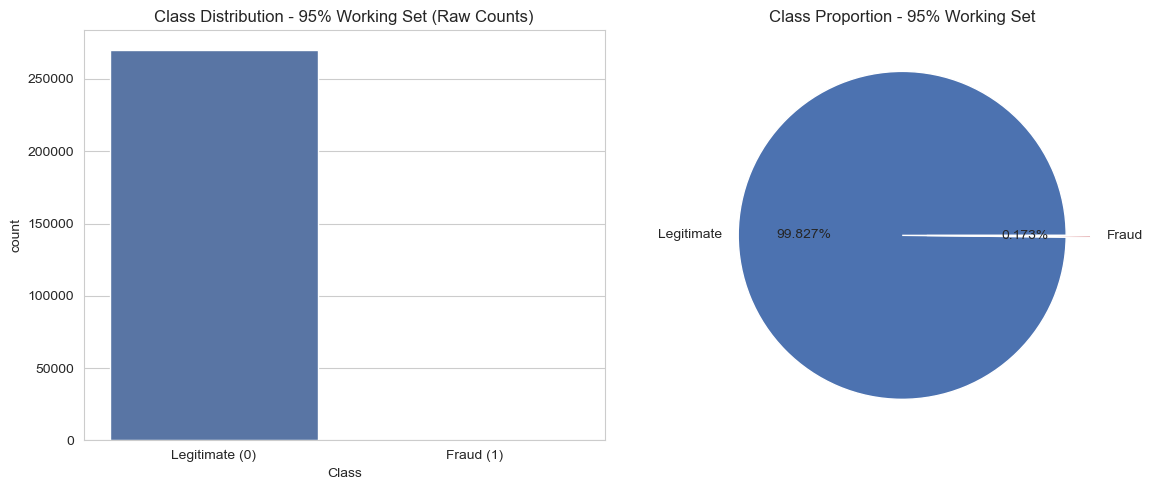

In [6]:
class_counts = df['Class'].value_counts()
fraud_pct = 100 * class_counts[1] / len(df)

print(f"Legitimate transactions (95% working set): {class_counts[0]:,}")
print(f"Fraudulent transactions (95% working set): {class_counts[1]:,}")
print(f"Fraud percentage: {fraud_pct:.4f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x='Class', data=df, ax=ax[0], hue='Class', palette=['#4c72b0', '#c44e52'], legend=False)
ax[0].set_title('Class Distribution - 95% Working Set (Raw Counts)')
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])

ax[1].pie(class_counts, labels=['Legitimate', 'Fraud'], autopct='%1.3f%%',
          colors=['#4c72b0', '#c44e52'], explode=[0, 0.15])
ax[1].set_title('Class Proportion - 95% Working Set')
plt.tight_layout()
plt.show()


**Block 7:** Compare transaction amounts for fraud vs legitimate (95% working data only)

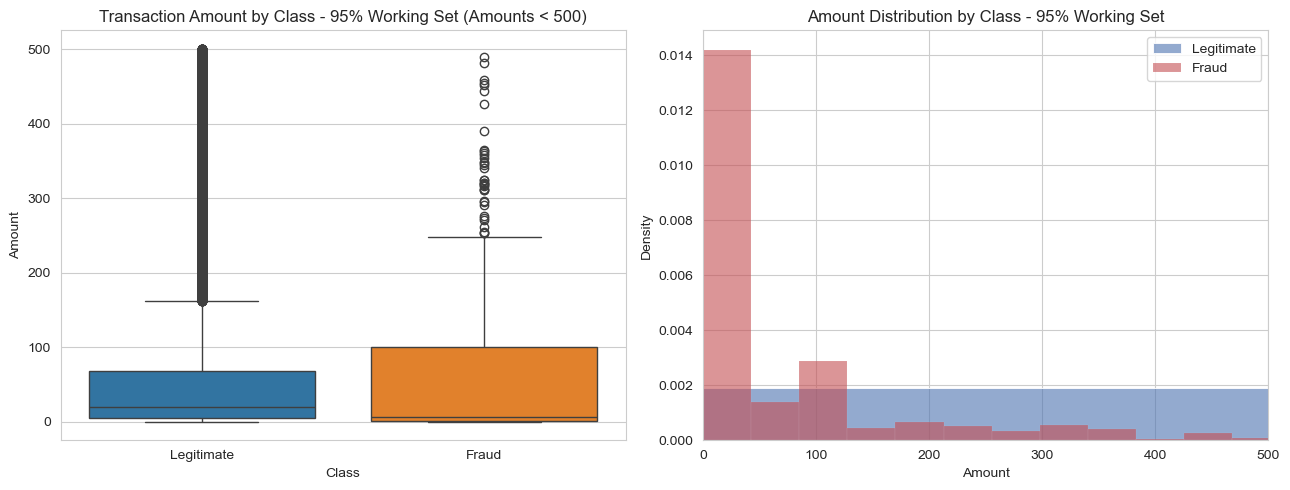

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      270099.0   88.184770  248.556318  0.0  5.65  22.00   77.05  25691.16
1         467.0  123.953662  261.701372  0.0  1.00   9.13  105.35   2125.87

Legit: mean £88.18, median £22.00 | Fraud: mean £123.95, median £9.13


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(x='Class', y='Amount', data=df[df['Amount'] < 500], hue='Class', ax=ax[0], legend=False)
ax[0].set_title('Transaction Amount by Class - 95% Working Set (Amounts < 500)')
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['Legitimate', 'Fraud'])

sns.histplot(df[df['Class']==0]['Amount'], bins=50, color='#4c72b0', label='Legitimate',
             stat='density', ax=ax[1], alpha=0.6)
sns.histplot(df[df['Class']==1]['Amount'], bins=50, color='#c44e52', label='Fraud',
             stat='density', ax=ax[1], alpha=0.6)
ax[1].set_xlim(0, 500)
ax[1].set_title('Amount Distribution by Class - 95% Working Set')
ax[1].legend()
plt.tight_layout()
plt.show()

print(df.groupby('Class')['Amount'].describe())

print(f"\nLegit: mean £{df[df['Class']==0]['Amount'].mean():.2f}, median £{df[df['Class']==0]['Amount'].median():.2f} | Fraud: mean £{df[df['Class']==1]['Amount'].mean():.2f}, median £{df[df['Class']==1]['Amount'].median():.2f}")

**Block 8:** Scale Amount and Time (fitted ONLY on the 95% working data), then split the
95% into 70% train / 25% test (of the ORIGINAL total). The scaler object is kept so it can later
be applied to the 5% holdout using these exact same parameters, without ever refitting on the
holdout itself.

In [8]:
scaler = StandardScaler()
df['scaled_amount'] = scaler.fit_transform(df['Amount'].values.reshape(-1, 1))
df['scaled_time'] = scaler.fit_transform(df['Time'].values.reshape(-1, 1))

df = df.drop(['Time', 'Amount'], axis=1)

X = df.drop('Class', axis=1)
y = df['Class']

# 70/95 of the working set = 70% of the ORIGINAL total; 25/95 = 25% of the original total
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=(0.25/0.95), random_state=RANDOM_STATE, stratify=y
)

print("Training set shape:", X_train.shape, f"({100*len(X_train)/len(df):.1f}% of the 95% working set)")
print("Test set shape:", X_test.shape, f"({100*len(X_test)/len(df):.1f}% of the 95% working set)")
print("\nFraud cases in training set:", y_train.sum())
print("Fraud cases in test set:", y_test.sum())


Training set shape: (199364, 30) (73.7% of the 95% working set)
Test set shape: (71202, 30) (26.3% of the 95% working set)

Fraud cases in training set: 344
Fraud cases in test set: 123


**Block 9:** Naive baseline model (no imbalance handling) demonstrates the accuracy trap

NAIVE BASELINE MODEL (no imbalance handling)

Accuracy:  0.9992
Precision: 0.8864
Recall:    0.6341
F1 Score:  0.7393


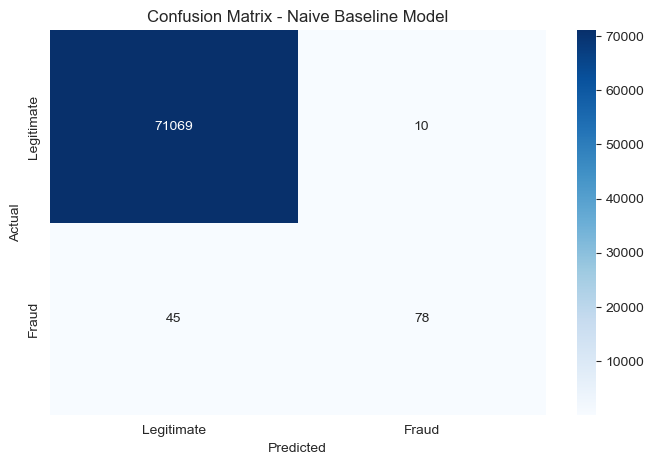

In [9]:
naive_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
naive_model.fit(X_train, y_train)
naive_pred = naive_model.predict(X_test)

print("NAIVE BASELINE MODEL (no imbalance handling)\n")
print(f"Accuracy:  {accuracy_score(y_test, naive_pred):.4f}")
print(f"Precision: {precision_score(y_test, naive_pred):.4f}")
print(f"Recall:    {recall_score(y_test, naive_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, naive_pred):.4f}")

cm = confusion_matrix(y_test, naive_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate', 'Fraud'], yticklabels=['Legitimate', 'Fraud'])
plt.title('Confusion Matrix - Naive Baseline Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


**Block 10:** Fix 1 of 3 - Class Weighting

In [10]:
lr_balanced = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
lr_balanced.fit(X_train, y_train)
pred_balanced = lr_balanced.predict(X_test)

print("LOGISTIC REGRESSION with class_weight='balanced'\n")
print(f"Accuracy:  {accuracy_score(y_test, pred_balanced):.4f}")
print(f"Precision: {precision_score(y_test, pred_balanced):.4f}")
print(f"Recall:    {recall_score(y_test, pred_balanced):.4f}")
print(f"F1 Score:  {f1_score(y_test, pred_balanced):.4f}")


LOGISTIC REGRESSION with class_weight='balanced'

Accuracy:  0.9772
Precision: 0.0650
Recall:    0.9106
F1 Score:  0.1214


**Block 11:** Fix 2 of 3 - SMOTE (oversampling)

In [11]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_smote.value_counts().to_dict())

lr_smote = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_smote.fit(X_train_smote, y_train_smote)
pred_smote = lr_smote.predict(X_test)

print("\nLOGISTIC REGRESSION with SMOTE\n")
print(f"Accuracy:  {accuracy_score(y_test, pred_smote):.4f}")
print(f"Precision: {precision_score(y_test, pred_smote):.4f}")
print(f"Recall:    {recall_score(y_test, pred_smote):.4f}")
print(f"F1 Score:  {f1_score(y_test, pred_smote):.4f}")


Before SMOTE: {0: 199020, 1: 344}
After SMOTE:  {0: 199020, 1: 199020}

LOGISTIC REGRESSION with SMOTE

Accuracy:  0.9761
Precision: 0.0622
Recall:    0.9106
F1 Score:  0.1164


**Block 12:** Fix 3 of 3 - Undersampling

In [12]:
undersampler = RandomUnderSampler(random_state=RANDOM_STATE)
X_train_under, y_train_under = undersampler.fit_resample(X_train, y_train)

print("Before undersampling:", y_train.value_counts().to_dict())
print("After undersampling: ", y_train_under.value_counts().to_dict())

lr_under = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_under.fit(X_train_under, y_train_under)
pred_under = lr_under.predict(X_test)

print("\nLOGISTIC REGRESSION with Undersampling\n")
print(f"Accuracy:  {accuracy_score(y_test, pred_under):.4f}")
print(f"Precision: {precision_score(y_test, pred_under):.4f}")
print(f"Recall:    {recall_score(y_test, pred_under):.4f}")
print(f"F1 Score:  {f1_score(y_test, pred_under):.4f}")


Before undersampling: {0: 199020, 1: 344}
After undersampling:  {0: 344, 1: 344}

LOGISTIC REGRESSION with Undersampling

Accuracy:  0.9677
Precision: 0.0463
Recall:    0.9024
F1 Score:  0.0881


**Block 13:** Compare all 3 imbalance-handling techniques side by side

           Naive (baseline)  Class Weighting   SMOTE  Undersampling
Accuracy             0.9992           0.9772  0.9761         0.9677
Precision            0.8864           0.0650  0.0622         0.0463
Recall               0.6341           0.9106  0.9106         0.9024
F1 Score             0.7393           0.1214  0.1164         0.0881


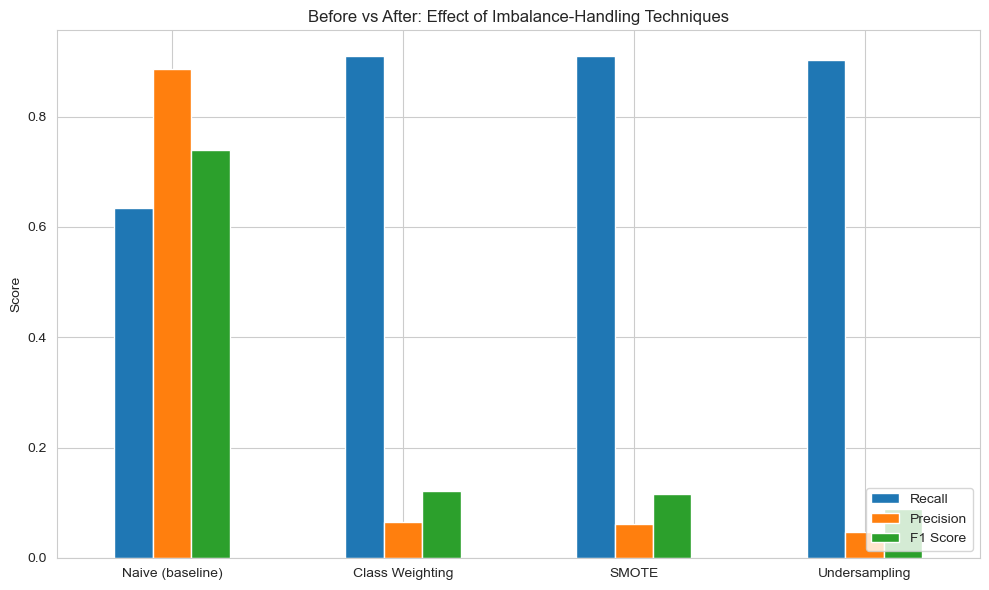

In [13]:
comparison = pd.DataFrame({
    'Naive (baseline)': [accuracy_score(y_test, naive_pred), precision_score(y_test, naive_pred),
                          recall_score(y_test, naive_pred), f1_score(y_test, naive_pred)],
    'Class Weighting': [accuracy_score(y_test, pred_balanced), precision_score(y_test, pred_balanced),
                         recall_score(y_test, pred_balanced), f1_score(y_test, pred_balanced)],
    'SMOTE': [accuracy_score(y_test, pred_smote), precision_score(y_test, pred_smote),
              recall_score(y_test, pred_smote), f1_score(y_test, pred_smote)],
    'Undersampling': [accuracy_score(y_test, pred_under), precision_score(y_test, pred_under),
                       recall_score(y_test, pred_under), f1_score(y_test, pred_under)],
}, index=['Accuracy', 'Precision', 'Recall', 'F1 Score'])

print(comparison.round(4))

comparison.T[['Recall', 'Precision', 'F1 Score']].plot(kind='bar', figsize=(10,6))
plt.title('Before vs After: Effect of Imbalance-Handling Techniques')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


**Block 14:** Compare all 4 algorithms - Logistic Regression, Decision Tree, Random Forest, XGBoost - trained on SMOTE-balanced data

In [14]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=10),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1)
}

results = {}
roc_data = {}

for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    results[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1 Score': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba)
    }
    roc_data[name] = roc_curve(y_test, proba)
    print(f"{name} done.")

results_df = pd.DataFrame(results).T
print("\nMODEL COMPARISON (trained on SMOTE-balanced data)\n")
print(results_df.round(4))


Logistic Regression done.
Decision Tree done.
Random Forest done.
XGBoost done.

MODEL COMPARISON (trained on SMOTE-balanced data)

                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.9761     0.0622  0.9106    0.1164   0.9779
Decision Tree          0.9899     0.1273  0.8293    0.2208   0.8975
Random Forest          0.9995     0.9074  0.7967    0.8485   0.9783
XGBoost                0.9992     0.7464  0.8374    0.7893   0.9803


**Block 15:** Bar chart comparing all 4 models across key metrics

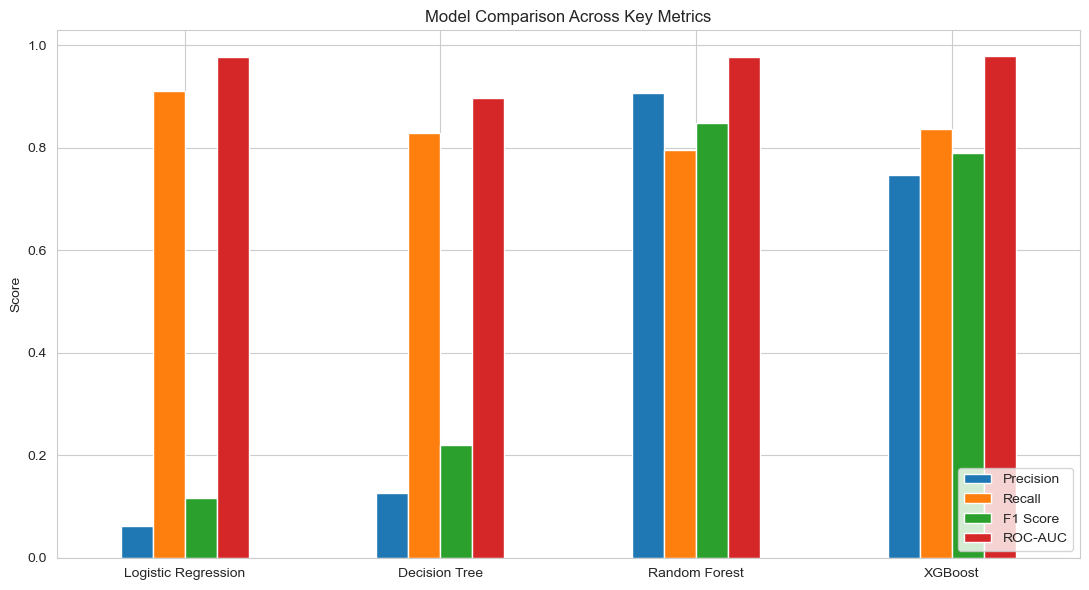

In [15]:
results_df[['Precision', 'Recall', 'F1 Score', 'ROC-AUC']].plot(kind='bar', figsize=(11,6))
plt.title('Model Comparison Across Key Metrics')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


**Block 16:** ROC curves for all 4 models

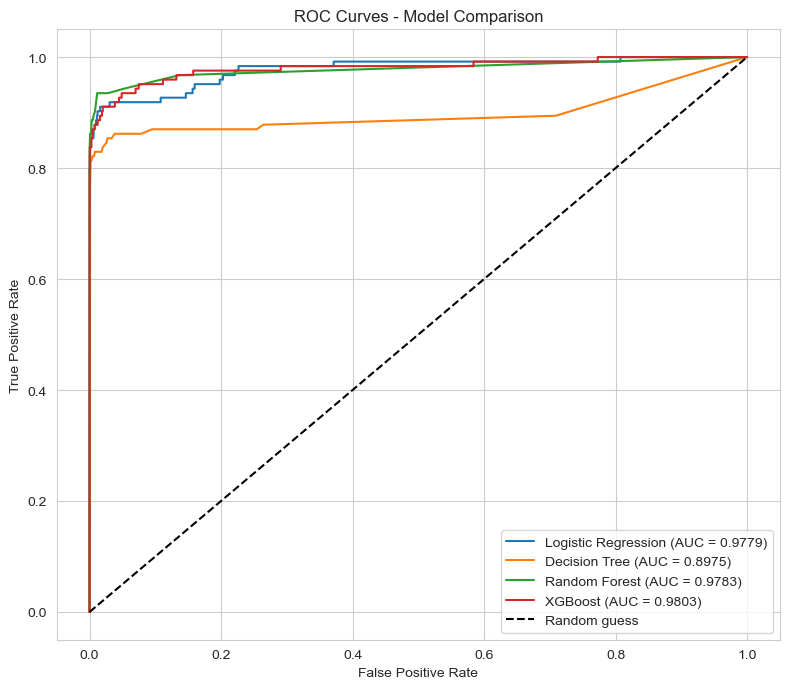

In [16]:
plt.figure(figsize=(8,7))
for name, (fpr, tpr, _) in roc_data.items():
    auc = results[name]['ROC-AUC']
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')
plt.plot([0,1],[0,1],'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison')
plt.legend()
plt.tight_layout()
plt.show()


**Block 17:** Confusion matrices for all 4 models side by side

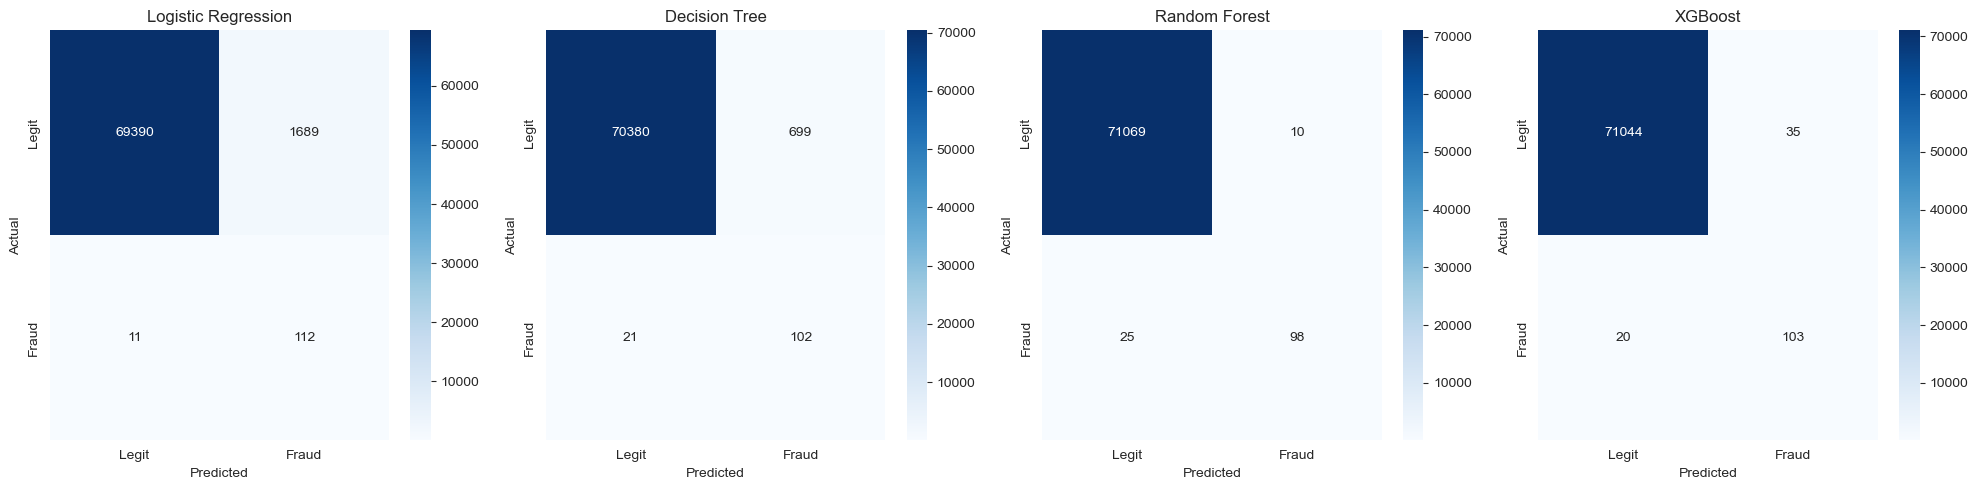

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(20,5))
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Legit','Fraud'], yticklabels=['Legit','Fraud'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()


**Block 18:** 5-fold cross-validation on Random Forest, using ONLY the 95% working data
(X, y) to verify results are consistent, not a fluke. The 5% holdout plays no part in this step.

Recall across 5 folds: [0.7979 0.7849 0.7527 0.828  0.7447]
Mean recall: 0.7816  (+/- 0.0304)


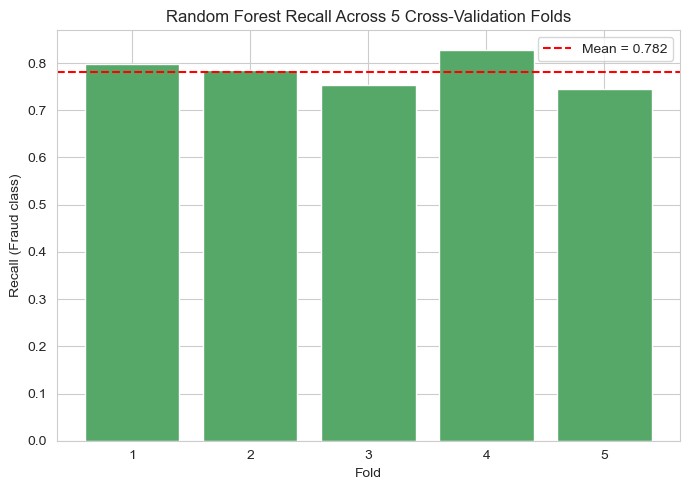

In [18]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf_cv = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

cv_scores = cross_val_score(rf_cv, X, y, cv=skf, scoring='recall', n_jobs=-1)

print("Recall across 5 folds:", np.round(cv_scores, 4))
print(f"Mean recall: {cv_scores.mean():.4f}  (+/- {cv_scores.std():.4f})")

plt.figure(figsize=(7,5))
plt.bar(range(1,6), cv_scores, color='#55a868')
plt.axhline(cv_scores.mean(), color='red', linestyle='--', label=f'Mean = {cv_scores.mean():.3f}')
plt.xlabel('Fold')
plt.ylabel('Recall (Fraud class)')
plt.title('Random Forest Recall Across 5 Cross-Validation Folds')
plt.legend()
plt.tight_layout()
plt.show()


**Block 19:** Feature importance - which columns the Random Forest relied on most (95% working data)

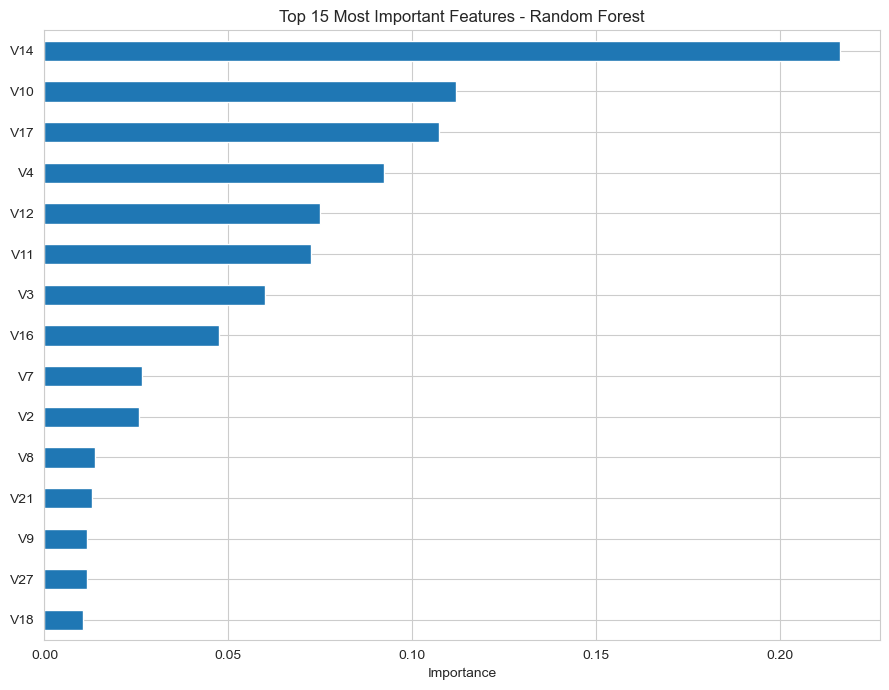

V14    0.216385
V10    0.111962
V17    0.107302
V4     0.092208
V12    0.074994
V11    0.072496
V3     0.059947
V16    0.047343
V7     0.026446
V2     0.025792
dtype: float64


In [19]:
rf_final = models['Random Forest']
importances = pd.Series(rf_final.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9,7))
importances.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 15 Most Important Features - Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(importances.head(10))


**Block 20:** FINAL step - the 5% holdout is used for the very first time here. It is scaled
using the SAME scaler fitted back in Block 8 on the 95% working data (never refit on the holdout
itself), then all four already-trained models are evaluated on it. This is a genuine test on data
that played no part whatsoever in exploration, scaling, training, testing, or cross-validation.

FINAL HOLDOUT VALIDATION (5% never seen at any prior stage)

Holdout set size: 14241 transactions, 25 fraud cases

                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.9985     0.5500    0.88    0.6769   0.9696
Decision Tree          0.9905     0.1275    0.76    0.2184   0.8363
Random Forest          0.9994     0.9048    0.76    0.8261   0.9697
XGBoost                0.9993     0.8261    0.76    0.7917   0.9679

Random Forest: Test Set vs Holdout Set

           Test Set (25%)  Holdout Set (5%, unseen)
Accuracy           0.9995                    0.9994
Precision          0.9074                    0.9048
Recall             0.7967                    0.7600
F1 Score           0.8485                    0.8261
ROC-AUC            0.9783                    0.9697

Random Forest (SMOTE-balanced) caught 19 out of 25 fraud cases in the holdout set.


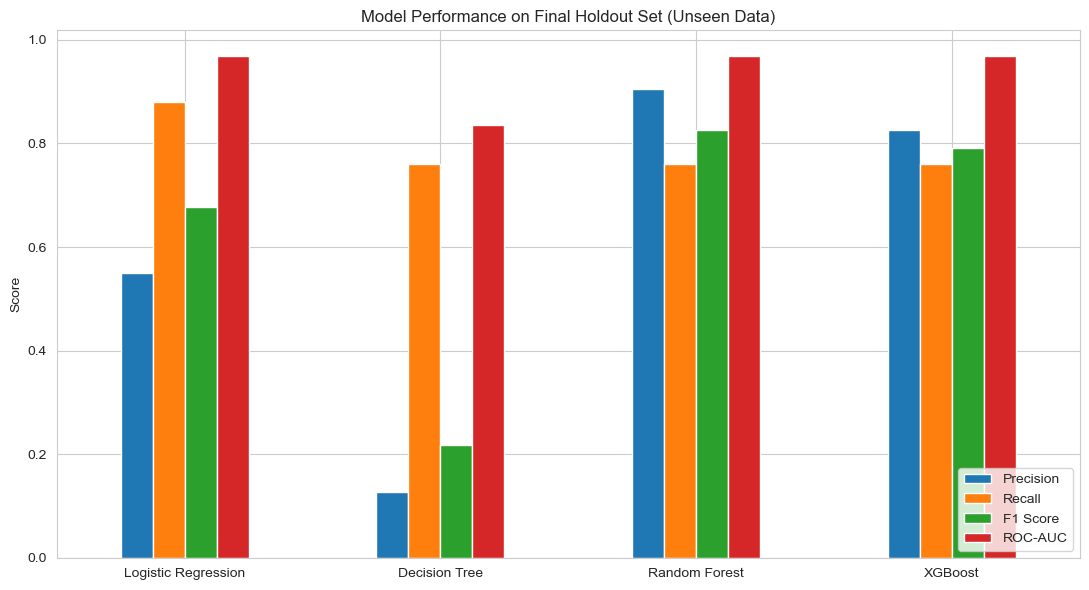

In [20]:
# Apply the SAME scaler (fitted only on the 95% working data in Block 8) to the holdout
X_holdout = X_holdout_raw.copy()
X_holdout['scaled_amount'] = scaler.transform(X_holdout['Amount'].values.reshape(-1, 1))
X_holdout['scaled_time'] = scaler.transform(X_holdout['Time'].values.reshape(-1, 1))
X_holdout = X_holdout.drop(['Time', 'Amount'], axis=1)
X_holdout = X_holdout[X_train.columns]  # ensure identical column order

holdout_results = {}

for name, model in models.items():
    pred_h = model.predict(X_holdout)
    proba_h = model.predict_proba(X_holdout)[:, 1]

    holdout_results[name] = {
        'Accuracy': accuracy_score(y_holdout, pred_h),
        'Precision': precision_score(y_holdout, pred_h),
        'Recall': recall_score(y_holdout, pred_h),
        'F1 Score': f1_score(y_holdout, pred_h),
        'ROC-AUC': roc_auc_score(y_holdout, proba_h)
    }

holdout_df = pd.DataFrame(holdout_results).T
print("FINAL HOLDOUT VALIDATION (5% never seen at any prior stage)\n")
print(f"Holdout set size: {len(X_holdout)} transactions, {y_holdout.sum()} fraud cases\n")
print(holdout_df.round(4))

comparison_holdout = pd.DataFrame({
    'Test Set (25%)': results_df.loc['Random Forest'],
    'Holdout Set (5%, unseen)': holdout_df.loc['Random Forest']
})
print("\nRandom Forest: Test Set vs Holdout Set\n")
print(comparison_holdout.round(4))

# Winning model (SMOTE + Random Forest) - fraud caught on the holdout
rf_pred_holdout = models['Random Forest'].predict(X_holdout)
rf_caught = ((rf_pred_holdout == 1) & (y_holdout == 1)).sum()
total_fraud_holdout = y_holdout.sum()
print(f"\nRandom Forest (SMOTE-balanced) caught {rf_caught} out of {total_fraud_holdout} fraud cases in the holdout set.")

holdout_df[['Precision', 'Recall', 'F1 Score', 'ROC-AUC']].plot(kind='bar', figsize=(11,6))
plt.title('Model Performance on Final Holdout Set (Unseen Data)')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()